# Part 1 | Data preprocessing

Place both original CSVs beside this notebook. In Colab, upload them to the Files panel. Run the cells from top to bottom.

This notebook inspects, cleans and merges weather and location data, then builds candidate features and exact next-day rainfall labels in millimetres. It exports the merged observations and the forecast dataset to `rainfall_outputs/`. Use `forecast_dataset.csv` as input to Part 2. Feature selection, imputation, scaling and encoding are fitted during training in Part 2.

Saved displays show results from the combined notebook run.

### Load the two CSV files

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
OUT = ROOT / 'rainfall_outputs'
OUT.mkdir(exist_ok=True)
weather = pd.read_csv(ROOT / 'weatherData.csv')
locations = pd.read_csv(ROOT / 'locationData.csv')

Matplotlib is building the font cache; this may take a moment.


### Exploratory data analysis | Missing values, types and duplicates

In [ ]:
for name, frame in [('weather', weather), ('locations', locations)]:
    print(name, frame.shape, 'exact duplicates:', frame.duplicated().sum())
    display(pd.DataFrame({'type': frame.dtypes.astype(str), 'missing': frame.isna().sum()}))

weather (142371, 21) exact duplicates: 0


,type,missing
location_id,int64,0
date,object,0
weather_code (wmo code),int64,0
temperature_2m_max (°C),float64,0
temperature_2m_min (°C),float64,0
temperature_2m_mean (°C),float64,0
apparent_temperature_max (°C),float64,0
apparent_temperature_min (°C),float64,0
apparent_temperature_mean (°C),float64,0
daylight_duration (s),float64,0


locations (27, 8) exact duplicates: 0


,type,missing
location_id,int64,0
latitude,float64,0
longitude,float64,0
elevation,int64,0
utc_offset_seconds,int64,0
timezone,object,0
timezone_abbreviation,int64,0
city_name,object,0


### Exploratory data analysis | Matplotlib histogram and boxplot

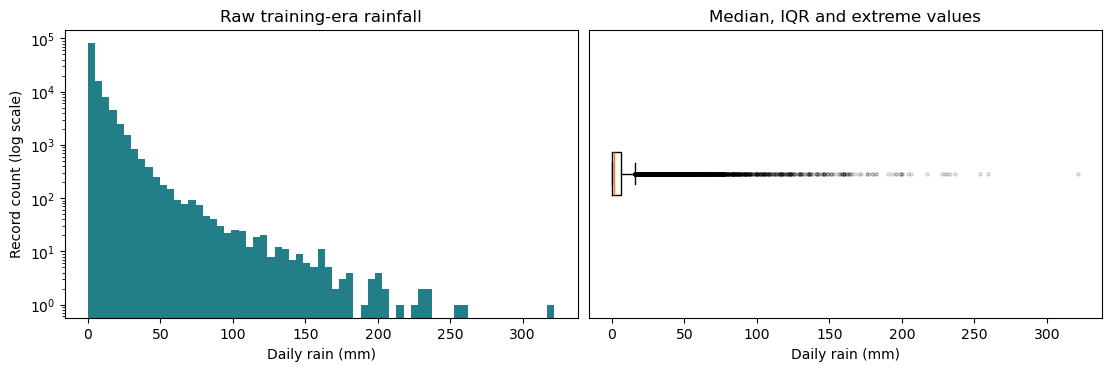

In [ ]:
# Initial EDA uses only the training era for rainfall distributions.
raw_rain = weather.loc[
    pd.to_datetime(weather['date'], format='%m/%d/%Y', errors='coerce') < '2022-01-01',
    'rain_sum (mm)'
].dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout='constrained')
axes[0].hist(raw_rain, bins=65, color='#227e87', log=True)
axes[0].set(xlabel='Daily rain (mm)', ylabel='Record count (log scale)', title='Raw training-era rainfall')
axes[1].boxplot(raw_rain, vert=False, flierprops={'markersize': 2, 'alpha': .2})
axes[1].set(xlabel='Daily rain (mm)', yticks=[], title='Median, IQR and extreme values')
plt.show()

## 1. Clean and merge
Lecture 3, slides 23–31: inspect types and missing values, remove exact duplicates, check outliers, split before learning transformations, impute, scale and encode. Merge weather with location metadata using the location ID. Conflicting keys or unmatched locations stop execution so they cannot silently distort the dataset. Dates are month/day/year, as shown by the source's day values above 12 in the second position.

### Duplicate removal | Validate dates and location IDs

In [ ]:
w = weather.drop_duplicates().copy()
loc = locations.drop_duplicates().copy()
w.columns = w.columns.str.split(' (', regex=False).str[0]
w['date'] = pd.to_datetime(w['date'], format='%m/%d/%Y', errors='coerce')
loc['city_name'] = loc['city_name'].astype('string').str.strip().replace('', pd.NA)
assert loc['location_id'].notna().all() and loc['location_id'].is_unique
assert loc['city_name'].notna().all()
invalid_keys = w[['date', 'location_id']].isna().any(axis=1)
print('Rows dropped for invalid keys:', invalid_keys.sum())
w = w.loc[~invalid_keys].copy()
assert not w.duplicated(['location_id', 'date']).any(), 'Conflicting location-date records'

Rows dropped for invalid keys: 0


### Type conversion | Check physically valid values

In [ ]:
for col in w.columns.difference(['date', 'location_id', 'sunrise', 'sunset']):
    w[col] = pd.to_numeric(w[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
for col in ['latitude', 'longitude', 'elevation']:
    loc[col] = pd.to_numeric(loc[col], errors='coerce').replace([np.inf, -np.inf], np.nan)

# Convert impossible negative values to missing; zero rainfall is valid.
nonnegative = ['rain_sum', 'precipitation_sum', 'precipitation_hours',
               'wind_speed_10m_max', 'wind_gusts_10m_max', 'shortwave_radiation_sum',
               'daylight_duration', 'sunshine_duration', 'et0_fao_evapotranspiration']
print('Invalid negative counts:', w[nonnegative].lt(0).sum().to_dict())
w[nonnegative] = w[nonnegative].mask(w[nonnegative].lt(0))
w['wind_direction_10m_dominant'] = w['wind_direction_10m_dominant'].where(
    w['wind_direction_10m_dominant'].between(0, 360))
w['precipitation_hours'] = w['precipitation_hours'].where(w['precipitation_hours'].le(24))

Invalid negative counts: {'rain_sum': 0, 'precipitation_sum': 0, 'precipitation_hours': 0, 'wind_speed_10m_max': 0, 'wind_gusts_10m_max': 0, 'shortwave_radiation_sum': 0, 'daylight_duration': 0, 'sunshine_duration': 0, 'et0_fao_evapotranspiration': 0}


### Data integration | Merge the two CSVs by location ID

In [ ]:
df = w.merge(loc, on='location_id', how='left', validate='many_to_one', indicator=True)
assert df['_merge'].eq('both').all(), 'Weather contains unknown location IDs'
df = df.drop(columns='_merge').sort_values(['location_id', 'date']).reset_index(drop=True)
df.to_csv(OUT / 'cleaned_merged_daily.csv', index=False)
print(len(df), 'rows;', df.location_id.nunique(), 'locations;',
      df.date.min().date(), 'to', df.date.max().date())
display(df['rain_sum'].describe(percentiles=[.5, .9, .95, .99]))

142371 rows; 27 locations; 2010-01-01 to 2024-06-08


count    142371.000000
mean          5.442717
std          10.286371
min           0.000000
50%           1.800000
90%          15.000000
95%          22.300000
99%          44.900000
max         321.800000
Name: rain_sum, dtype: float64

## 2. Build the forecast rows
The target is joined by exact calendar date, so missing dates cannot turn a next-day forecast into a multi-day forecast. Yesterday and 3-day rainfall use exact dates too. Rain today is valid at this forecast cutoff; weather code, precipitation totals/hours, sunrise/sunset and redundant summaries are excluded from the model. Retain real heavy rain: an IQR flag is diagnostic, not a reason to delete a plausible storm.

### Look up rain by location and date

In [ ]:
df['target_date'] = df['date'] + pd.Timedelta(days=1)
key = ['location_id', 'date']
rain = df.set_index(key)['rain_sum']
def rain_at(dates):
    lookup = pd.MultiIndex.from_arrays([df['location_id'], dates])
    return rain.reindex(lookup).to_numpy()

### Feature engineering | Rainfall lags and next-day target

In [ ]:
df['rain_next_day_mm'] = rain_at(df['target_date'])
df['rain_yesterday_mm'] = rain_at(df['date'] - pd.Timedelta(days=1))
rain_two_days_ago = rain_at(df['date'] - pd.Timedelta(days=2))
df['rain_3day_mean_mm'] = (df['rain_sum'] + df['rain_yesterday_mm'] + rain_two_days_ago) / 3

### Feature engineering | Cyclical encoding and temperature range

In [ ]:
season = 2 * np.pi * (df['target_date'].dt.dayofyear - 1) / 365.25
df['season_sin'], df['season_cos'] = np.sin(season), np.cos(season)
direction = np.deg2rad(df['wind_direction_10m_dominant'])
df['wind_sin'], df['wind_cos'] = np.sin(direction), np.cos(direction)
df['temperature_range'] = df['temperature_2m_max'] - df['temperature_2m_min']
df['temperature_range'] = df['temperature_range'].where(df['temperature_range'].ge(0))

### Feature screening | Choose inputs available at forecast time

In [ ]:
NUM = ['latitude', 'longitude', 'elevation', 'rain_sum', 'rain_yesterday_mm',
       'rain_3day_mean_mm', 'season_sin', 'season_cos', 'wind_sin', 'wind_cos',
       'temperature_2m_mean', 'temperature_range', 'sunshine_duration',
       'wind_speed_10m_max', 'wind_gusts_10m_max', 'shortwave_radiation_sum',
       'et0_fao_evapotranspiration']
FEATURES = NUM + ['city_name']
TARGET = 'rain_next_day_mm'
data = df.dropna(subset=[TARGET]).copy()
print('Rows without next-day label:', len(df) - len(data), '| Candidate inputs:', len(FEATURES))

Rows without next-day label: 27 | Candidate inputs: 18


### Chronological splitting | Training, validation and test

In [ ]:
train = data[data.target_date < '2022-01-01']
val = data[data.target_date.between('2022-01-01', '2022-12-31')]
test = data[data.target_date >= '2023-01-01']
assert len(train) and len(val) and len(test)
assert train.target_date.max() < val.target_date.min() < test.target_date.min()
for name, part in [('train', train), ('validation', val), ('test', test)]:
    print(name, len(part), part.target_date.min().date(), part.target_date.max().date())

train 118314 2010-01-02 2021-12-31
validation 9855 2022-01-01 2022-12-31
test 14175 2023-01-01 2024-06-08


### Outlier detection | Flag extreme rainfall using the IQR rule

In [ ]:
q1, q3 = train[TARGET].quantile([.25, .75])
fence = q3 + 1.5 * (q3 - q1)
print(f'Training upper IQR fence: {fence:.2f} mm; {train[TARGET].gt(fence).sum():,} flagged and retained')
data['split'] = 'test'
data.loc[train.index, 'split'] = 'train'
data.loc[val.index, 'split'] = 'validation'
data[['date', 'target_date', 'location_id', 'split', *FEATURES, TARGET]].to_csv(
    OUT / 'forecast_dataset.csv', index=False)

Training upper IQR fence: 15.85 mm; 10,423 flagged and retained


## 3. Preprocessing techniques fitted on training data

These cells demonstrate the transformations on the training split and apply them to validation data. The exported forecast CSV keeps the original candidate inputs. Part 2 fits these steps again inside each model pipeline so each validation fold learns its own settings.

### Missing-value treatment | Median imputation

Fill missing numeric values using the training median. Missing target values were removed earlier because they cannot supervise the model.

In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median', keep_empty_features=True)
train_imputed = imputer.fit_transform(train[NUM])
val_imputed = imputer.transform(val[NUM])

print('Missing training values before:', train[NUM].isna().sum().sum())
print('Missing training values after:', np.isnan(train_imputed).sum())

### Feature selection | Keep the 12 highest-scoring numeric inputs

Rank numeric inputs by their association with rainfall using training labels. City is kept separately.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression

selector = SelectKBest(f_regression, k=12)
train_selected = selector.fit_transform(train_imputed, train[TARGET])
val_selected = selector.transform(val_imputed)

selected_names = selector.get_feature_names_out(NUM)
print('Selected numeric inputs:', ', '.join(selected_names))

### Feature scaling | Standardization

Learn the mean and standard deviation from training inputs. Ridge and KNN use scaled values. Tree models use the selected values on their original scales.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_selected)
val_scaled = scaler.transform(val_selected)

display(pd.DataFrame(train_scaled[:5], columns=selected_names).round(2))

### Categorical encoding | One-hot encode city

Give each city its own indicator column. Apply the training city categories to the validation set.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
train_city = encoder.fit_transform(train[['city_name']])
val_city = encoder.transform(val[['city_name']])

print('City indicator columns:', train_city.shape[1])
print('Total model inputs after encoding:', train_scaled.shape[1] + train_city.shape[1])